# Feature Analysis — run `analyze_features.py` from this notebook

This notebook runs the feature-analysis script (`src/analyze_features.py`) and shows its output inline — both the **text summary** and the **plots**.

Running the cells regenerates everything into `src/dataset/processed/feature_analysis/`:

- `01`–`02` class distribution (linear + log)
- `03`–`04` class distribution over time (counts + proportions)
- `05`–`06` source/destination ports by class
- `07` Spearman correlation matrix
- `08` scatter matrix
- `feature_analysis_summary.md` — the text digest

In [ ]:
from pathlib import Path
import sys

# Make `src/` importable so `analyze_features` (and its `load_data` import) resolve.
# The kernel's working directory may be the repo root or the notebooks/ folder,
# so try a few candidates and pick the one that actually contains the script.
_candidates = [
    Path.cwd() / "src",
    Path.cwd().parent / "src",
    Path(__file__).resolve().parent.parent / "src" if "__file__" in globals() else None,
]
SRC_DIR = next(
    (c for c in _candidates if c is not None and (c / "analyze_features.py").is_file()),
    None,
)
if SRC_DIR is None:
    raise FileNotFoundError("Could not locate src/analyze_features.py from the notebook.")
if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))

import matplotlib.pyplot as plt
from IPython.display import display, Markdown as display_md, HTML, Image

import analyze_features as af

# Where the script writes its PNGs and the text summary.
OUT = af.OUTPUT_DIR
SUMMARY_MD = OUT / "feature_analysis_summary.md"

print("src dir:", SRC_DIR)
print("output dir:", OUT)

In [ ]:
# Run the full analysis. This loads the dataset, builds every plot, and writes
# the text summary (feature_analysis_summary.md).
af.main()

## Text summary

The machine- and human-readable digest the script generated:

In [7]:
display_md(SUMMARY_MD.read_text(encoding="utf-8"))

# UNSW-NB15 Feature Analysis - Text Summary

Dataset shape: **2,540,047** flows x **50** columns. Generated by `src/analyze_features.py`.

This file summarizes the accompanying PNG plots in text so they can be reviewed without opening the images.

## 1. Class distribution

Total flows: **2,540,047** across **10** classes.

| class_name | flows | % of flows |
| --- | --- | --- |
| Benign | 2218764 | 87.35 |
| Generic | 215481 | 8.48 |
| Exploits | 44525 | 1.75 |
| Fuzzers | 24246 | 0.95 |
| DoS | 16353 | 0.64 |
| Reconnaissance | 13987 | 0.55 |
| Analysis | 2677 | 0.11 |
| Backdoor | 2329 | 0.09 |
| Shellcode | 1511 | 0.06 |
| Worms | 174 | 0.01 |

## 2. Class distribution over time (30-minute bins)

Time range: **2015-01-22 11:30:00** to **2015-02-18 12:00:00** (51 bins).

Total flows per class:

| class_name | total |
| --- | --- |
| Benign | 2218764 |
| Generic | 215481 |
| Exploits | 44525 |
| Fuzzers | 24246 |
| DoS | 16353 |
| Reconnaissance | 13987 |
| Analysis | 2677 |
| Backdoor | 2329 |
| Shellcode | 1511 |
| Worms | 174 |

Peak share of each class within a 30-min bin:

| class | peak bin | peak share |
| --- | --- | --- |
| Analysis | 2015-01-22 12:30 | 0.91% |
| Backdoor | 2015-01-22 12:30 | 0.94% |
| Benign | 2015-01-22 14:00 | 100.00% |
| DoS | 2015-02-18 00:00 | 6.29% |
| Exploits | 2015-02-18 00:00 | 8.86% |
| Fuzzers | 2015-01-22 12:30 | 3.93% |
| Generic | 2015-02-18 05:30 | 32.07% |
| Reconnaissance | 2015-02-18 00:00 | 2.00% |
| Shellcode | 2015-01-22 11:30 | 0.14% |
| Worms | 2015-01-22 11:30 | 0.02% |

### Top 15 `sport` ports by class

| port | flows | share | dominant class | dominant share |
| --- | --- | --- | --- | --- |
| 1043 | 220,322 | 45.51% | Generic | 50.52% |
| 47439 | 203,269 | 41.99% | Benign | 51.57% |
| 0 | 54,044 | 11.16% | Exploits | 30.02% |
| 138 | 3,480 | 0.72% | Benign | 100.00% |
| 5060 | 523 | 0.11% | Benign | 90.44% |
| 2048 | 404 | 0.08% | Benign | 96.78% |
| 137 | 381 | 0.08% | Fuzzers | 100.00% |
| 80 | 378 | 0.08% | Benign | 98.15% |
| 53 | 257 | 0.05% | Benign | 79.38% |
| 6881 | 215 | 0.04% | Benign | 99.07% |
| 68 | 210 | 0.04% | Exploits | 40.48% |
| 5190 | 180 | 0.04% | Benign | 99.44% |
| 65535 | 161 | 0.03% | Benign | 45.96% |
| 25 | 137 | 0.03% | Benign | 100.00% |
| 1025 | 134 | 0.03% | Benign | 80.60% |

### Top 15 `dsport` ports by class

| port | flows | share | dominant class | dominant share |
| --- | --- | --- | --- | --- |
| 53 | 798,968 | 46.94% | Benign | 73.68% |
| 80 | 226,698 | 13.32% | Benign | 91.30% |
| 6881 | 125,156 | 7.35% | Benign | 100.00% |
| 5190 | 120,599 | 7.08% | Benign | 99.97% |
| 111 | 93,296 | 5.48% | Benign | 89.68% |
| 25 | 88,748 | 5.21% | Benign | 94.03% |
| 0 | 54,091 | 3.18% | Exploits | 30.00% |
| 143 | 51,065 | 3.00% | Benign | 96.44% |
| 22 | 50,827 | 2.99% | Benign | 99.96% |
| 21 | 50,518 | 2.97% | Benign | 93.82% |
| 179 | 20,099 | 1.18% | Benign | 69.41% |
| 520 | 8,973 | 0.53% | Benign | 60.36% |
| 445 | 6,187 | 0.36% | Fuzzers | 78.62% |
| 514 | 3,557 | 0.21% | Fuzzers | 52.04% |
| 138 | 3,501 | 0.21% | Benign | 99.40% |

## 4. Strongest feature correlations (Spearman, off-diagonal)

Features in matrix: **37**. Top 15 by |corr| (with each feature's documented description):

**trans_depth <-> ct_flw_http_mthd** — 0.999
- `trans_depth`: Represents the pipelined depth into the connection of http request/response transaction
- `ct_flw_http_mthd`: No. of flows that has methods such as Get and Post in http service.

**swin <-> dwin** — 0.997
- `swin`: Source TCP window advertisement value
- `dwin`: Destination TCP window advertisement value

**tcprtt <-> synack** — 0.983
- `tcprtt`: TCP connection setup round-trip time, the sum of ’synack’ and ’ackdat’.
- `synack`: TCP connection setup time, the time between the SYN and the SYN_ACK packets.

**Spkts <-> Dpkts** — 0.970
- `Spkts`: Source to destination packet count
- `Dpkts`: Destination to source packet count

**dloss <-> Spkts** — 0.966
- `dloss`: Destination packets retransmitted or dropped
- `Spkts`: Source to destination packet count

**dloss <-> Dpkts** — 0.965
- `dloss`: Destination packets retransmitted or dropped
- `Dpkts`: Destination to source packet count

**dbytes <-> Dpkts** — 0.965
- `dbytes`: Destination to source transaction bytes
- `Dpkts`: Destination to source packet count

**trans_depth <-> res_bdy_len** — 0.947
- `trans_depth`: Represents the pipelined depth into the connection of http request/response transaction
- `res_bdy_len`: Actual uncompressed content size of the data transferred from the server’s http service.

**dbytes <-> dloss** — 0.941
- `dbytes`: Destination to source transaction bytes
- `dloss`: Destination packets retransmitted or dropped

**sloss <-> Spkts** — 0.941
- `sloss`: Source packets retransmitted or dropped
- `Spkts`: Source to destination packet count

**res_bdy_len <-> ct_flw_http_mthd** — 0.940
- `res_bdy_len`: Actual uncompressed content size of the data transferred from the server’s http service.
- `ct_flw_http_mthd`: No. of flows that has methods such as Get and Post in http service.

**tcprtt <-> ackdat** — 0.939
- `tcprtt`: TCP connection setup round-trip time, the sum of ’synack’ and ’ackdat’.
- `ackdat`: TCP connection setup time, the time between the SYN_ACK and the ACK packets.

**Sintpkt <-> Dintpkt** — 0.936
- `Sintpkt`: Source interpacket arrival time (mSec)
- `Dintpkt`: Destination interpacket arrival time (mSec)

**sloss <-> dloss** — 0.935
- `sloss`: Source packets retransmitted or dropped
- `dloss`: Destination packets retransmitted or dropped

**dur <-> Dintpkt** — 0.935
- `dur`: Record total duration
- `Dintpkt`: Destination interpacket arrival time (mSec)

## 5. Scatter-matrix features (descriptive statistics)

Features plotted: **dur, sbytes, dbytes, sttl, dttl, tcprtt** (log1p-transformed if nonnegative).

|  | count | mean | std | min | 50% | max |
| --- | --- | --- | --- | --- | --- | --- |
| dur | 2,000.0000 | 0.6058 | 3.6093 | 0.0000 | 0.0149 | 59.9913 |
| sbytes | 2,000.0000 | 3,495.6880 | 7,474.4310 | 46.0000 | 1,470.0000 | 68,195.0000 |
| dbytes | 2,000.0000 | 31,608.4810 | 135,324.3912 | 0.0000 | 1,768.0000 | 1,094,788.0000 |
| sttl | 2,000.0000 | 60.8240 | 72.2813 | 0.0000 | 31.0000 | 254.0000 |
| dttl | 2,000.0000 | 29.5275 | 39.5415 | 0.0000 | 29.0000 | 252.0000 |
| tcprtt | 2,000.0000 | 0.0056 | 0.0354 | 0.0000 | 0.0006 | 0.7179 |


## Plots

Rendered inline from the PNG files the script saved.

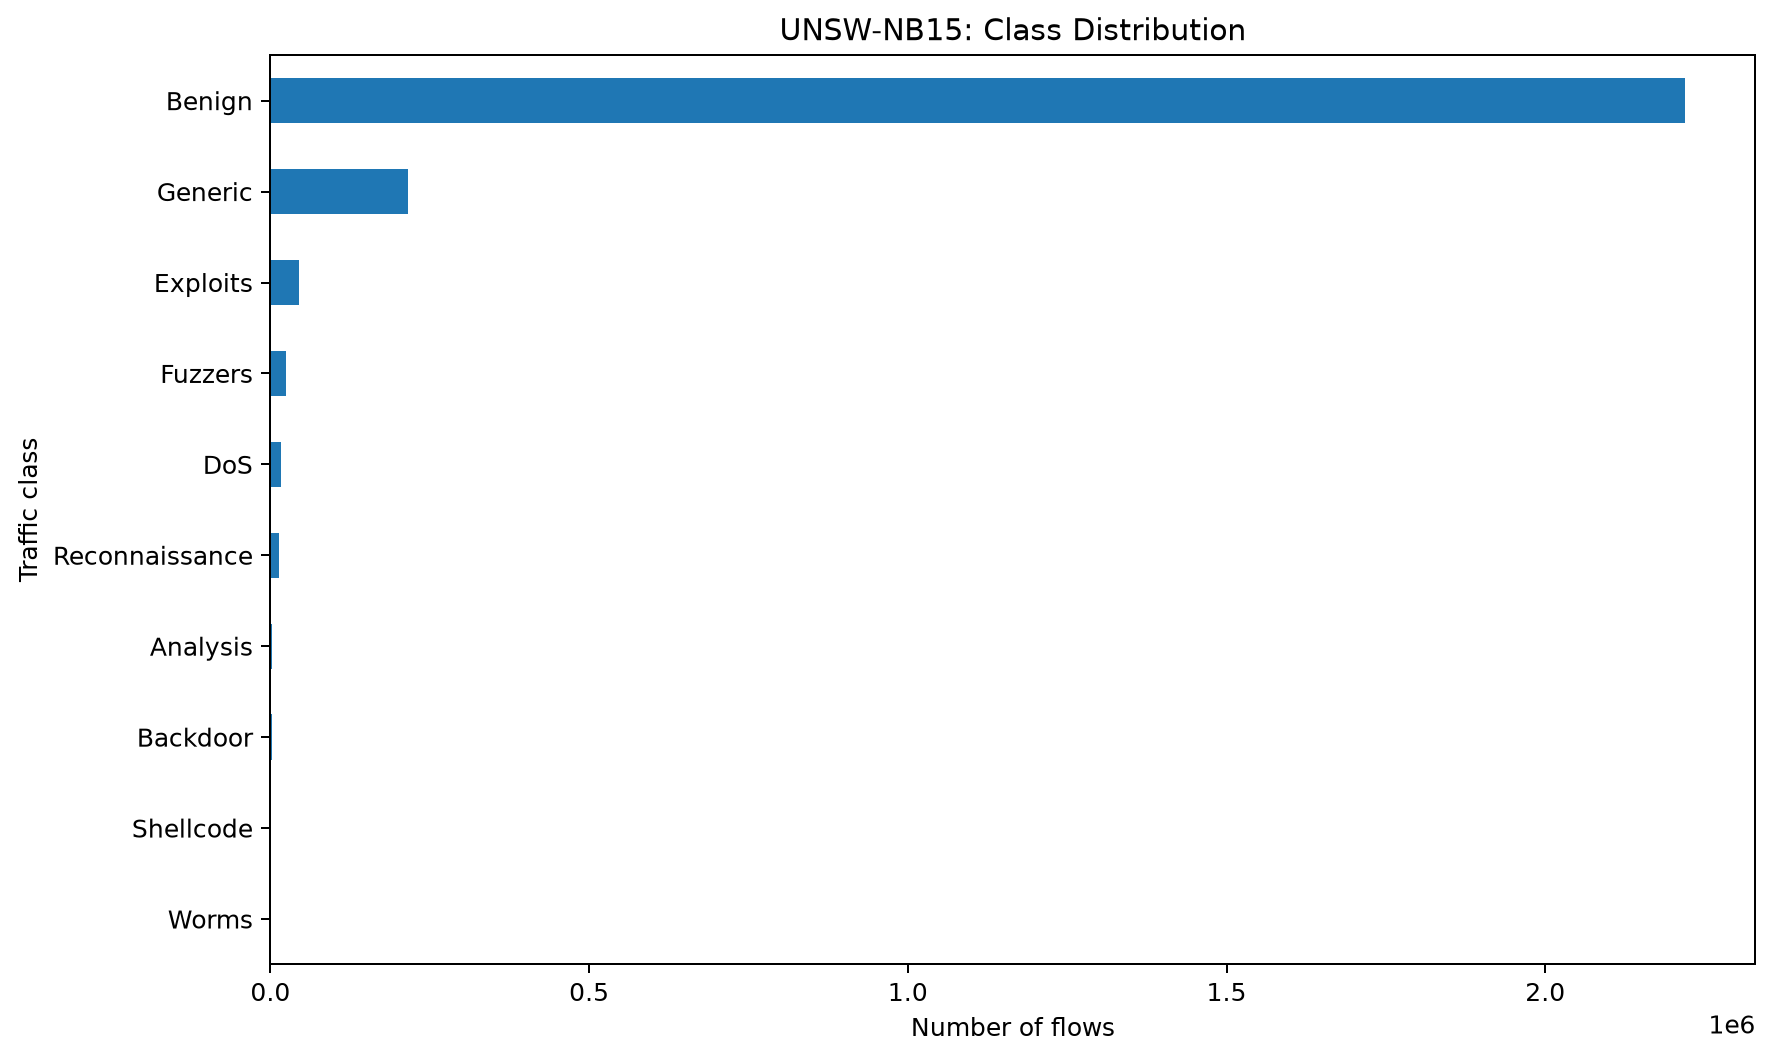

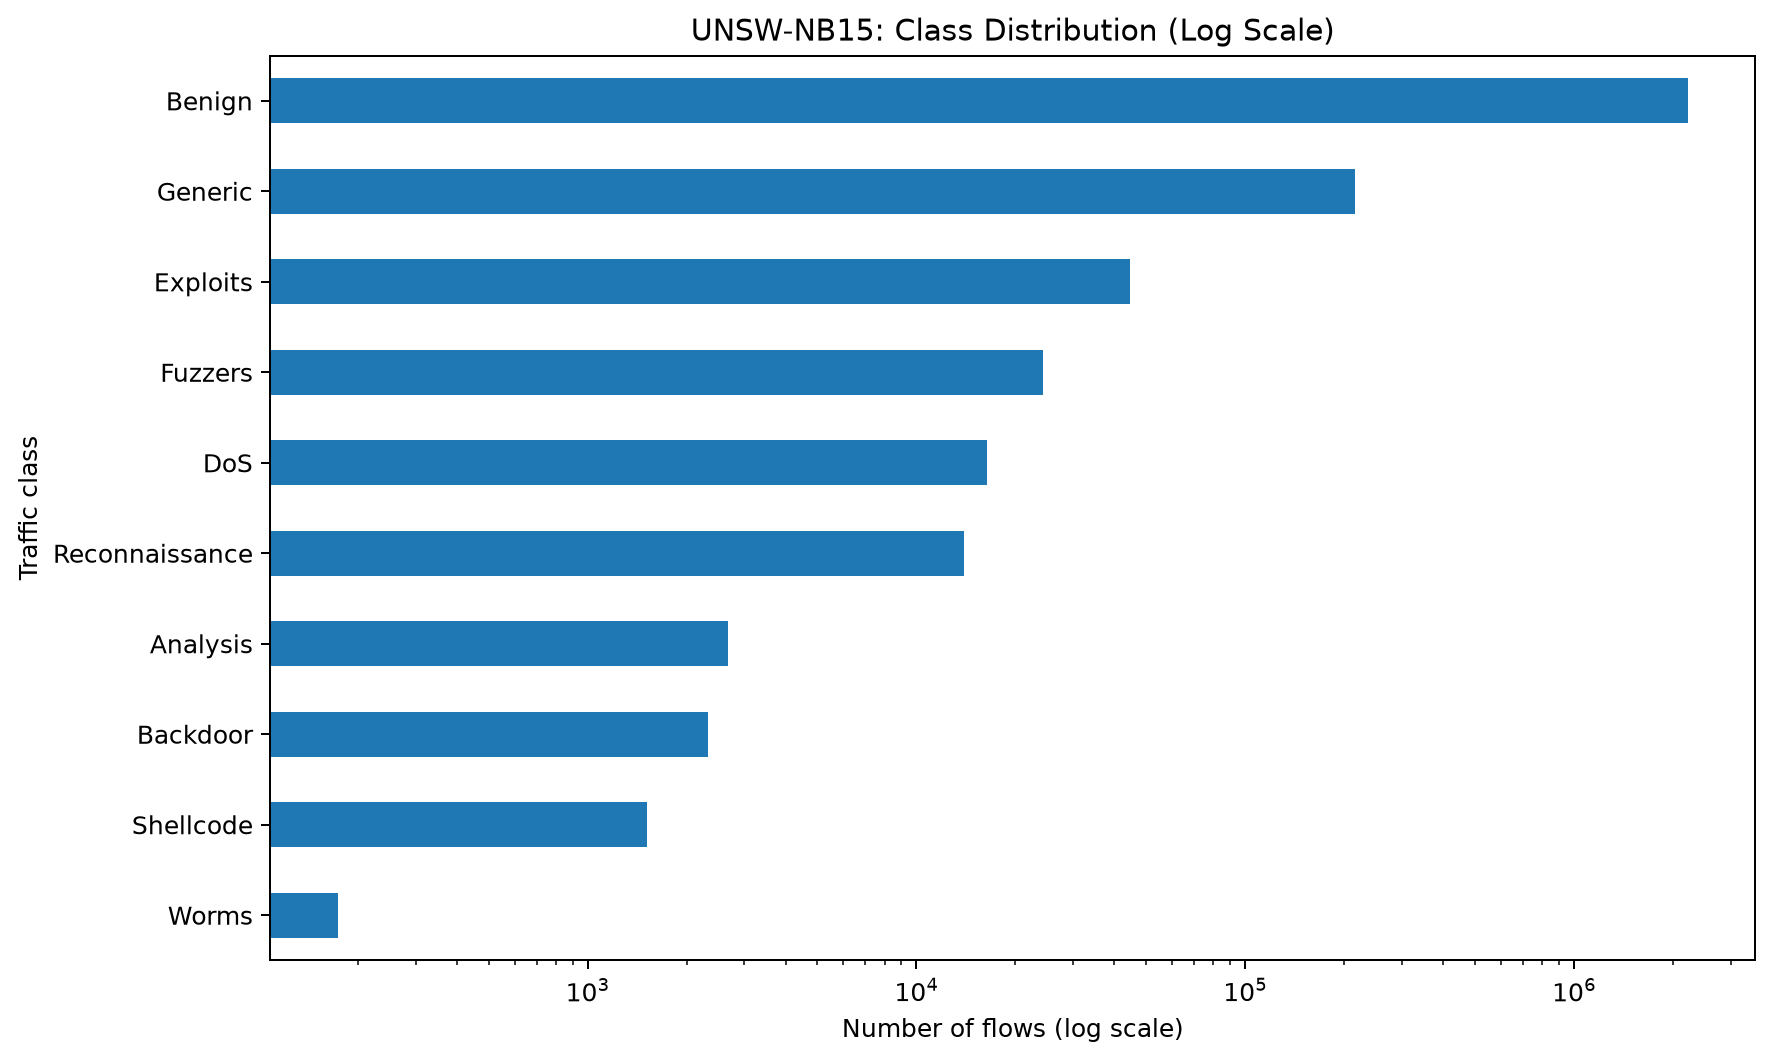

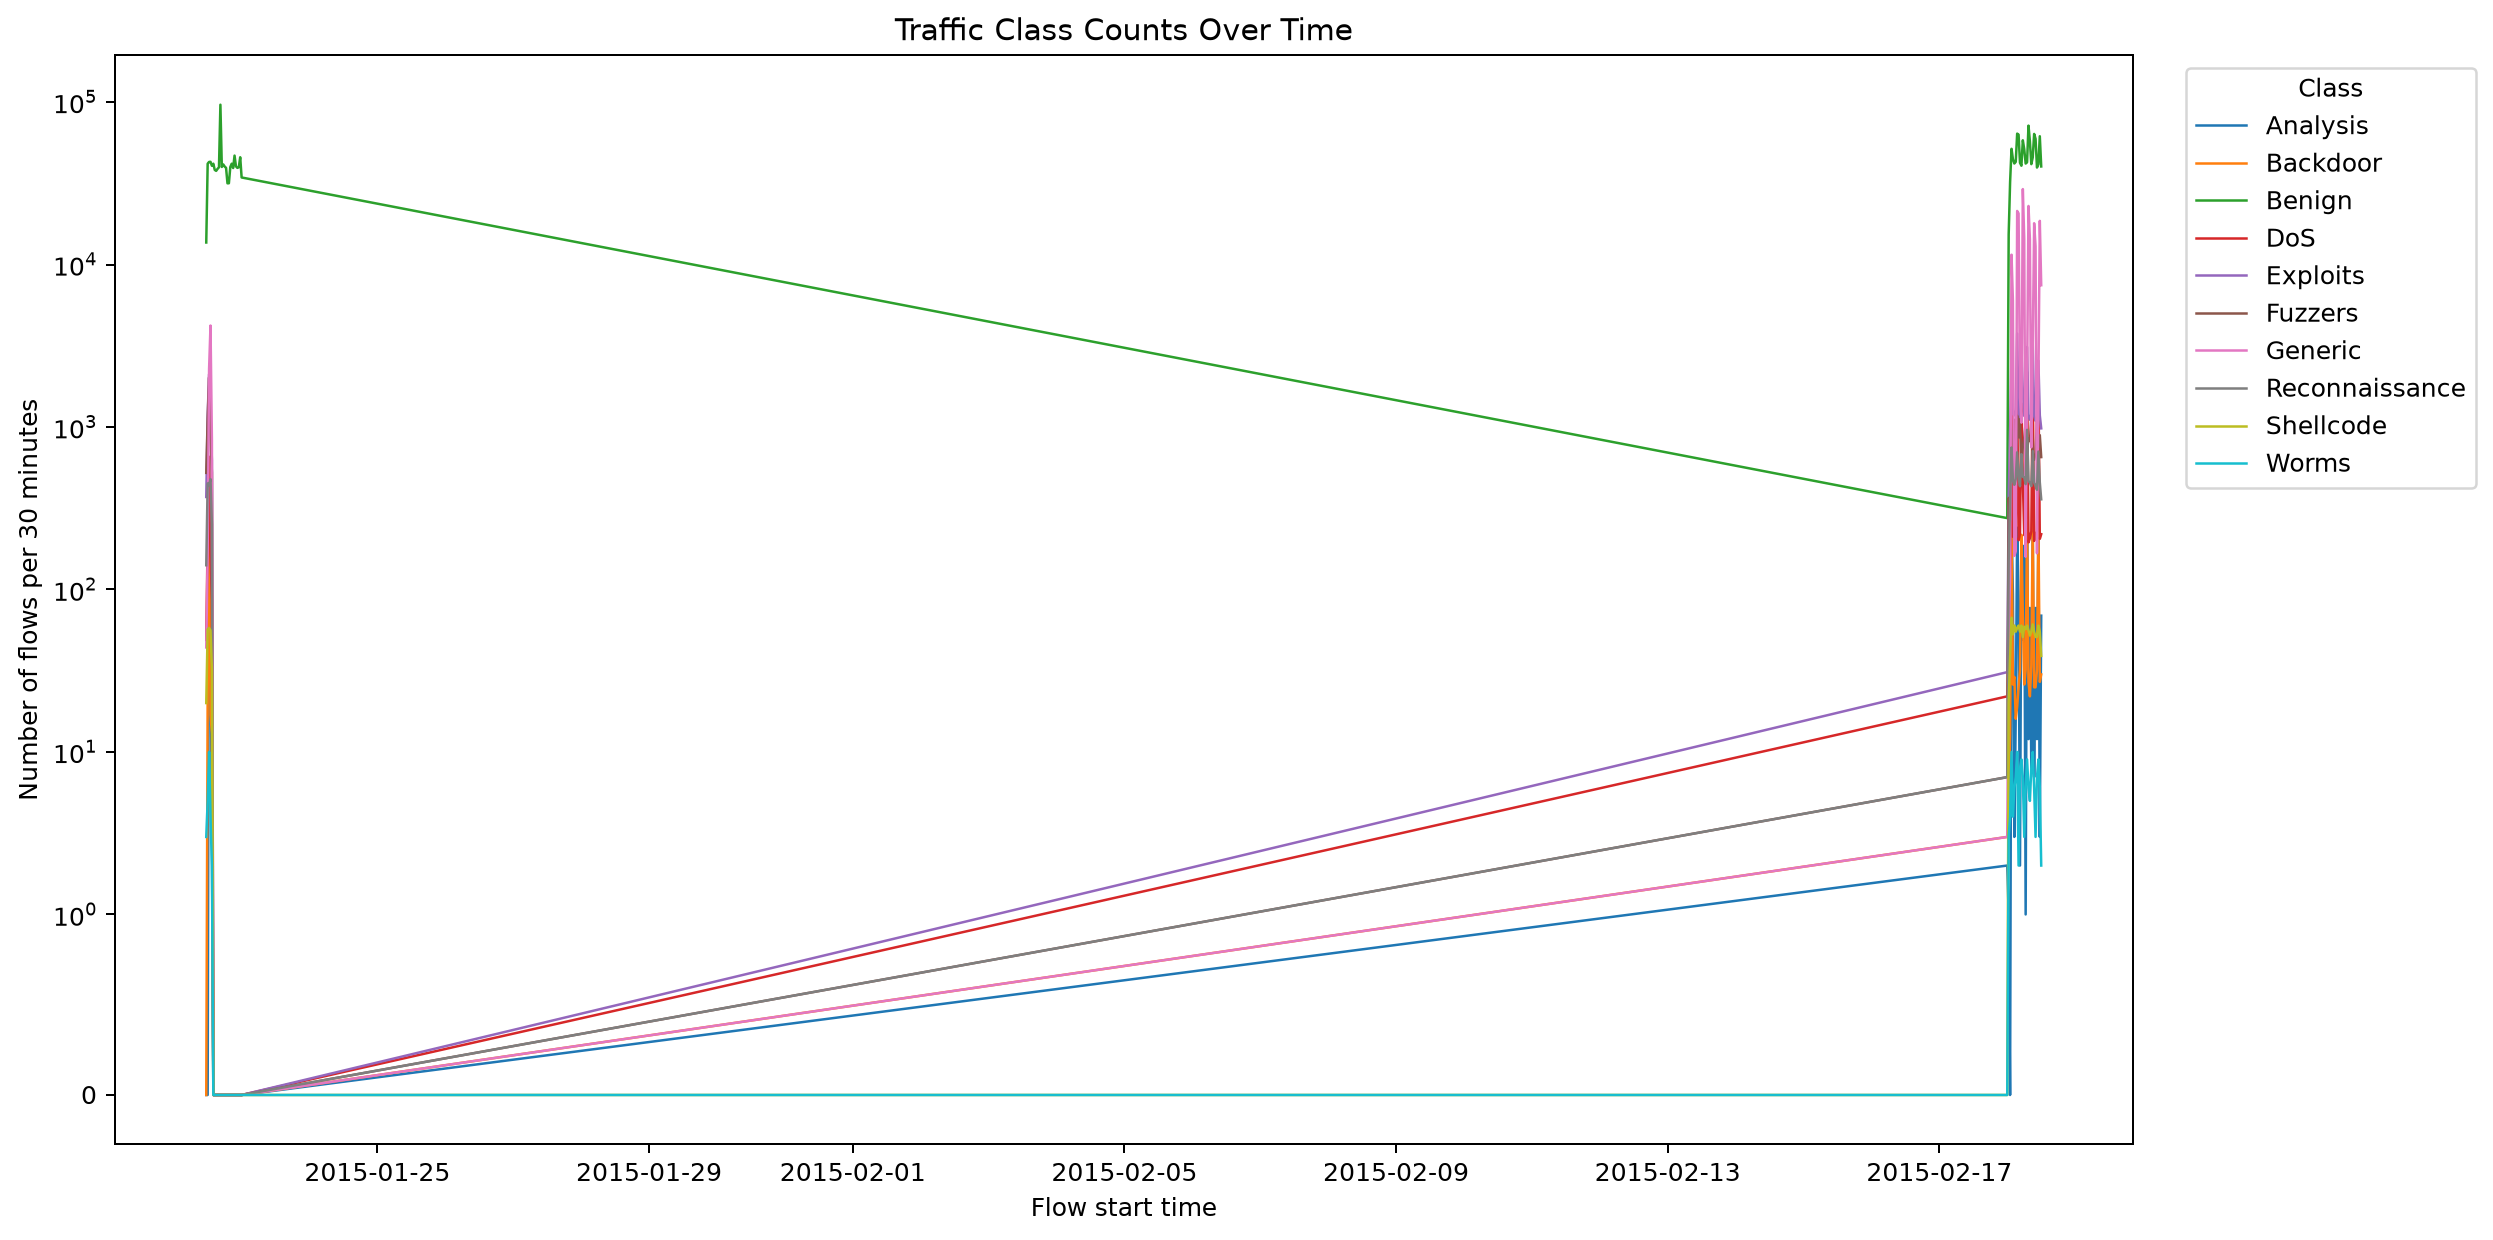

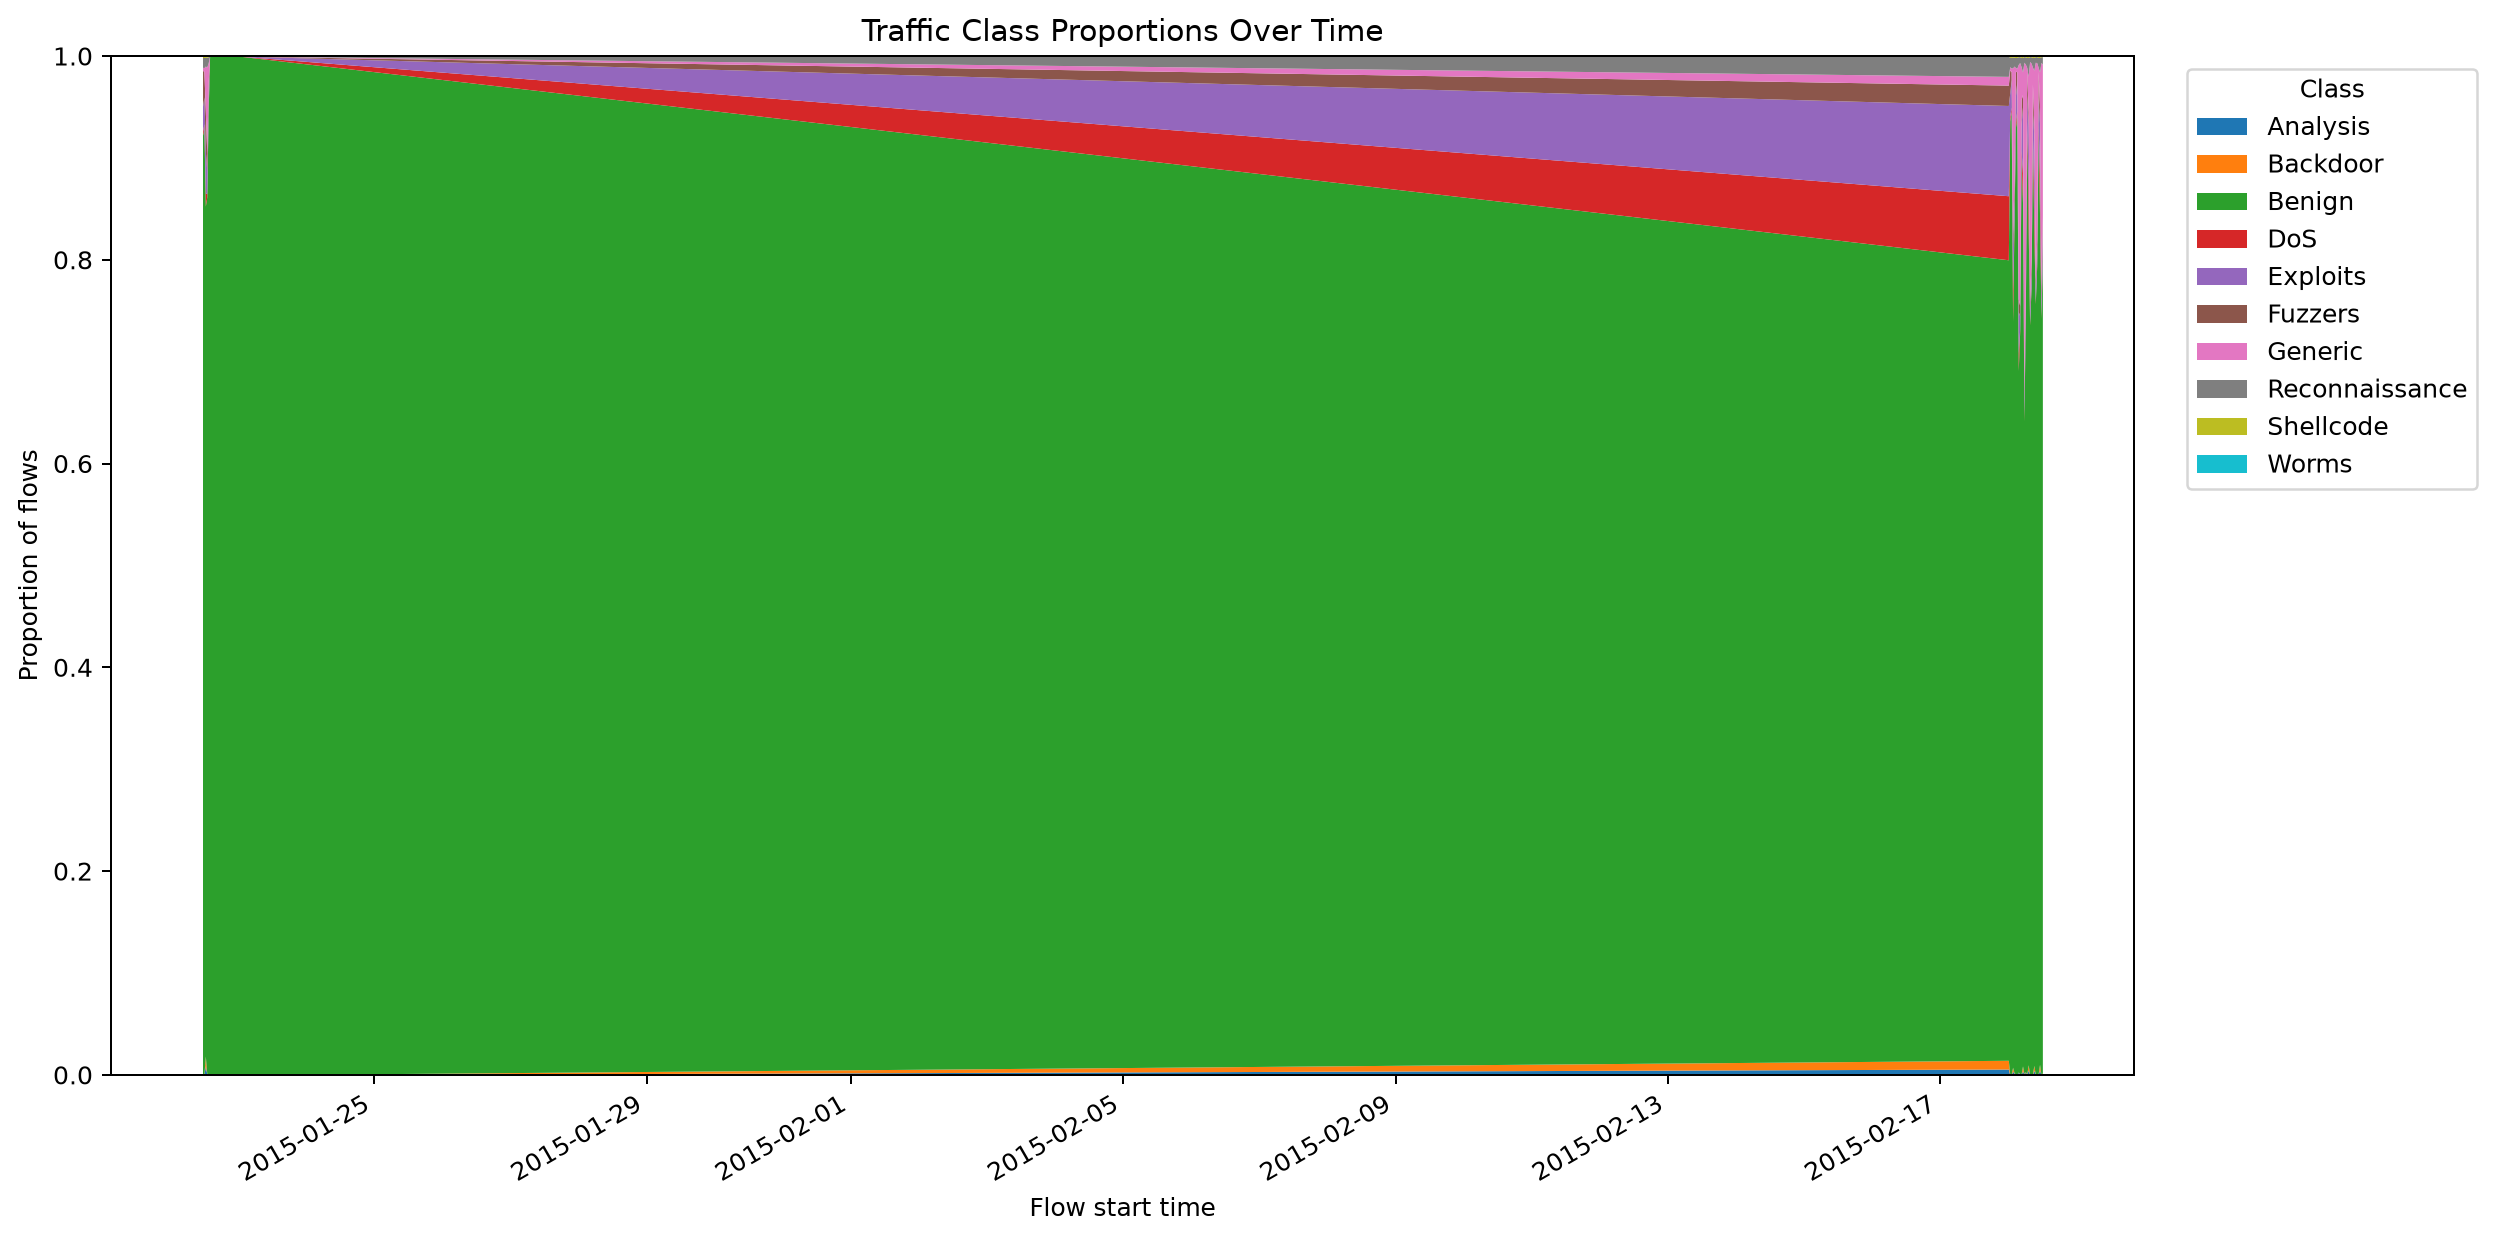

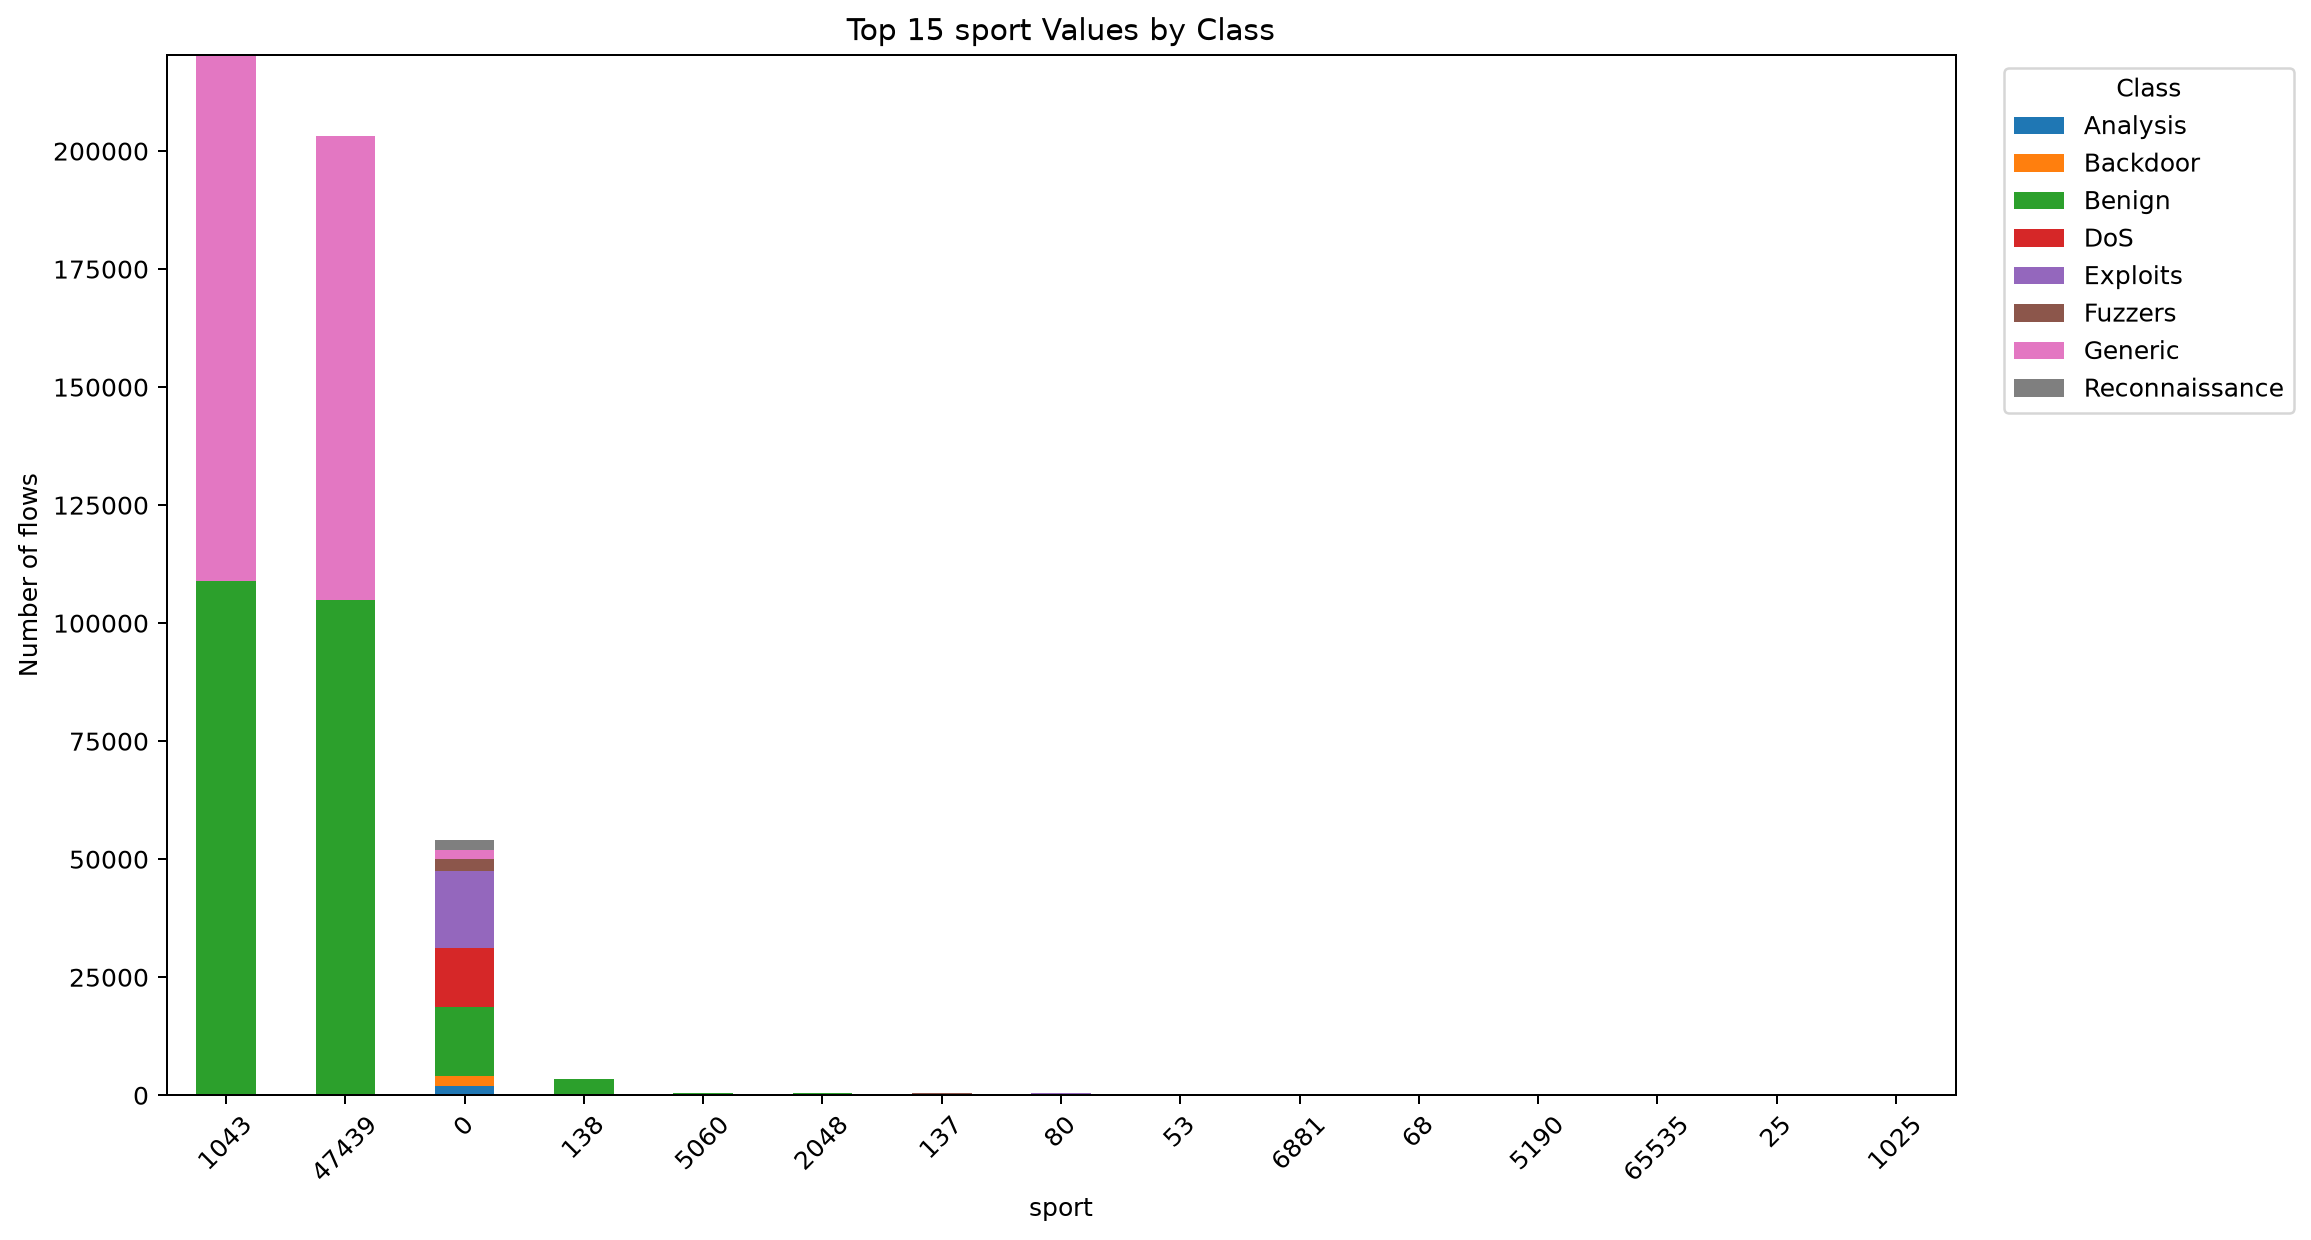

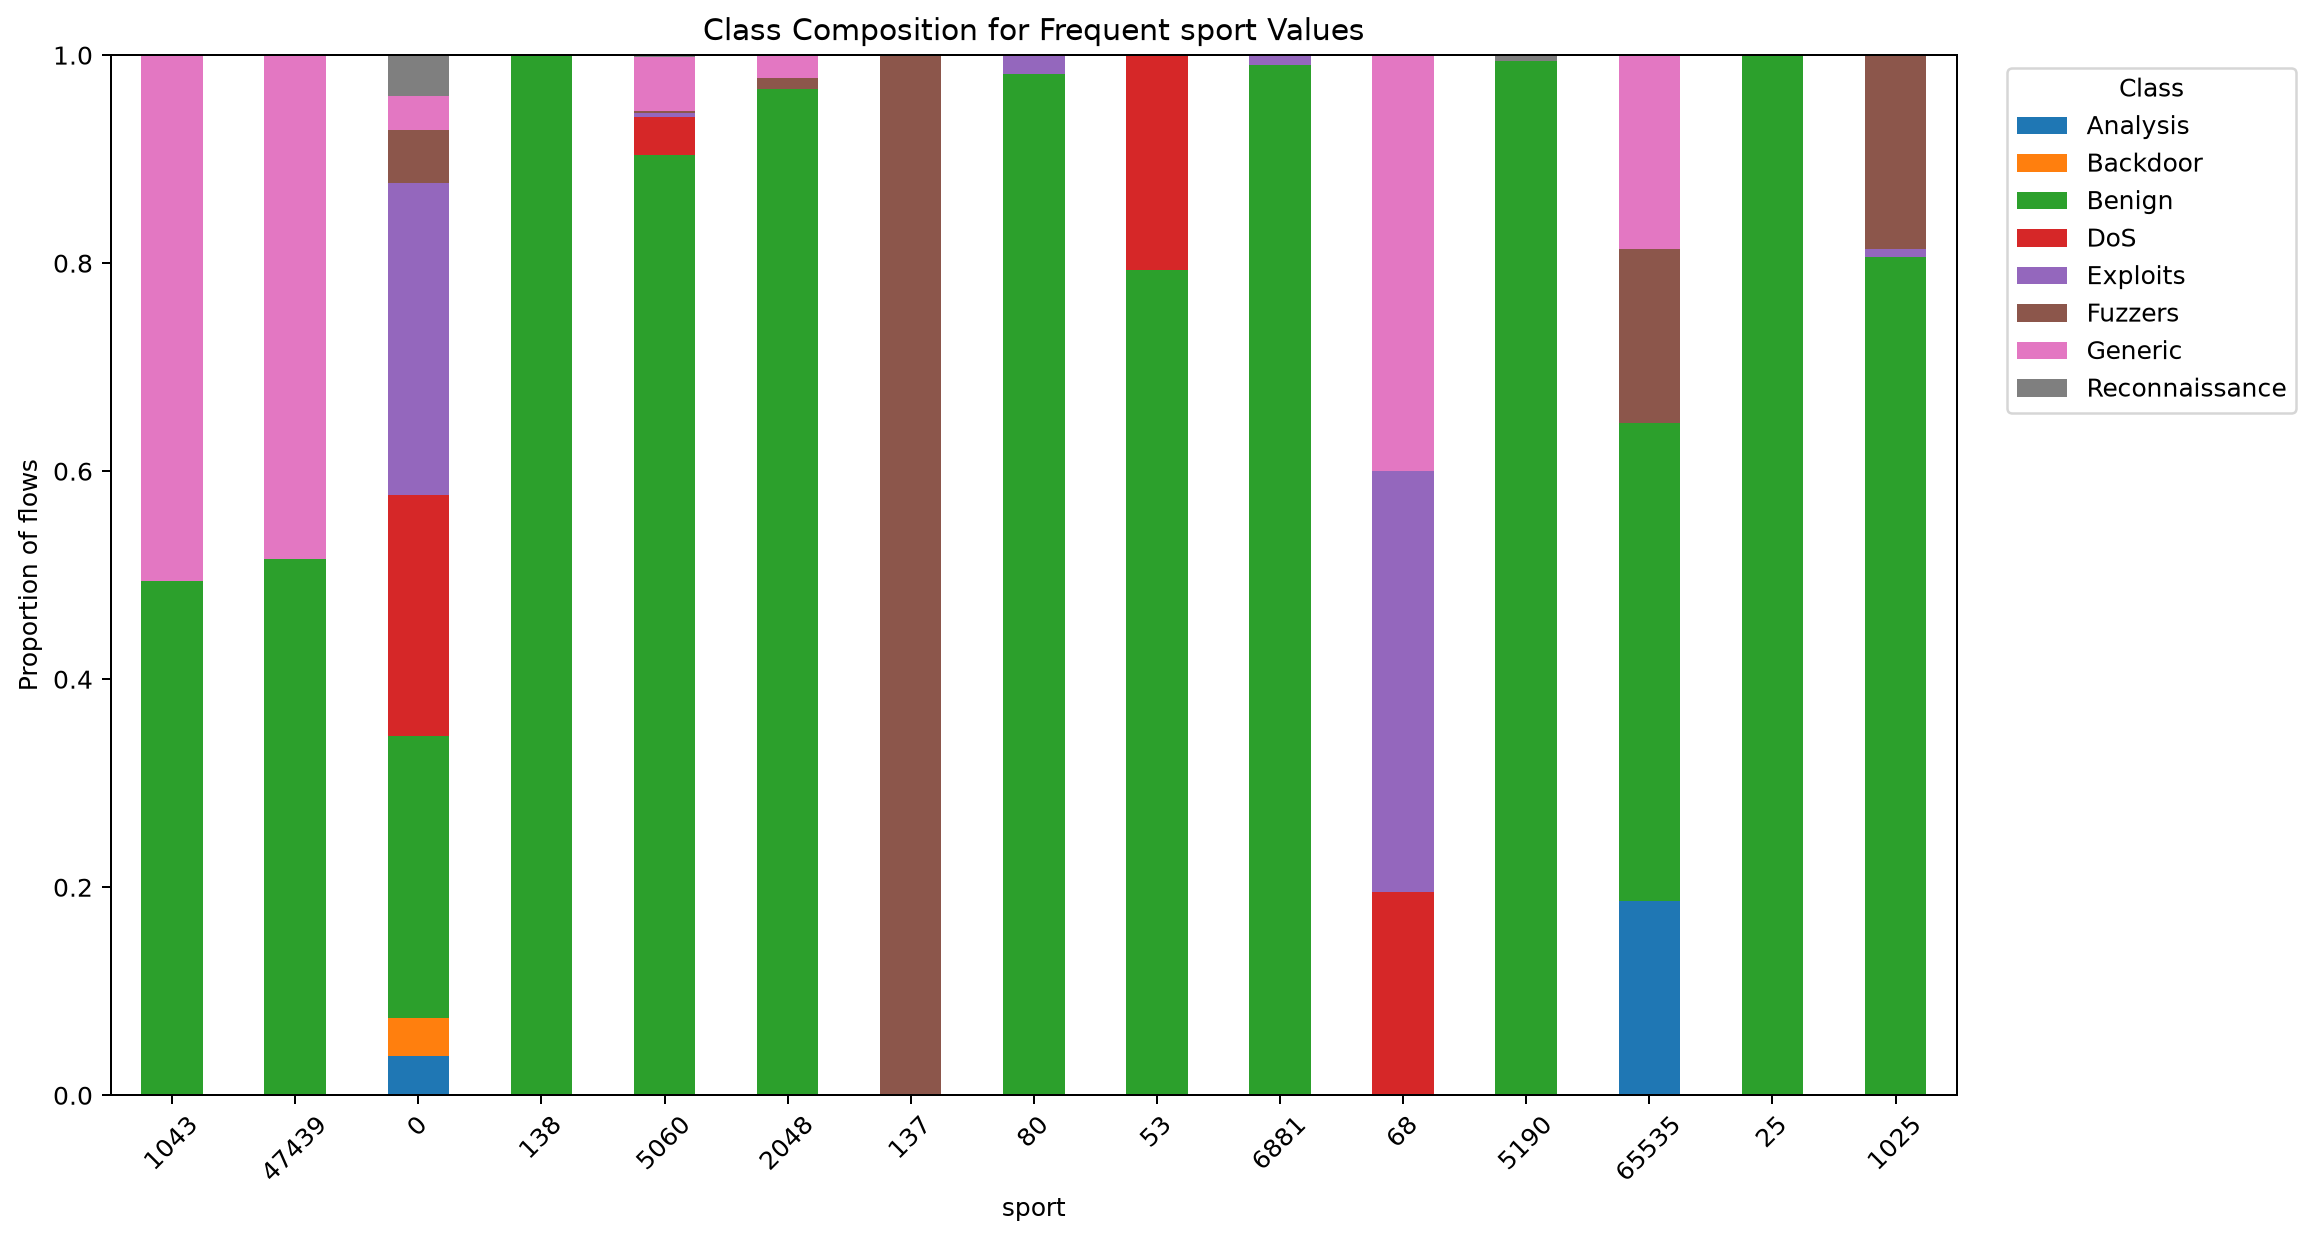

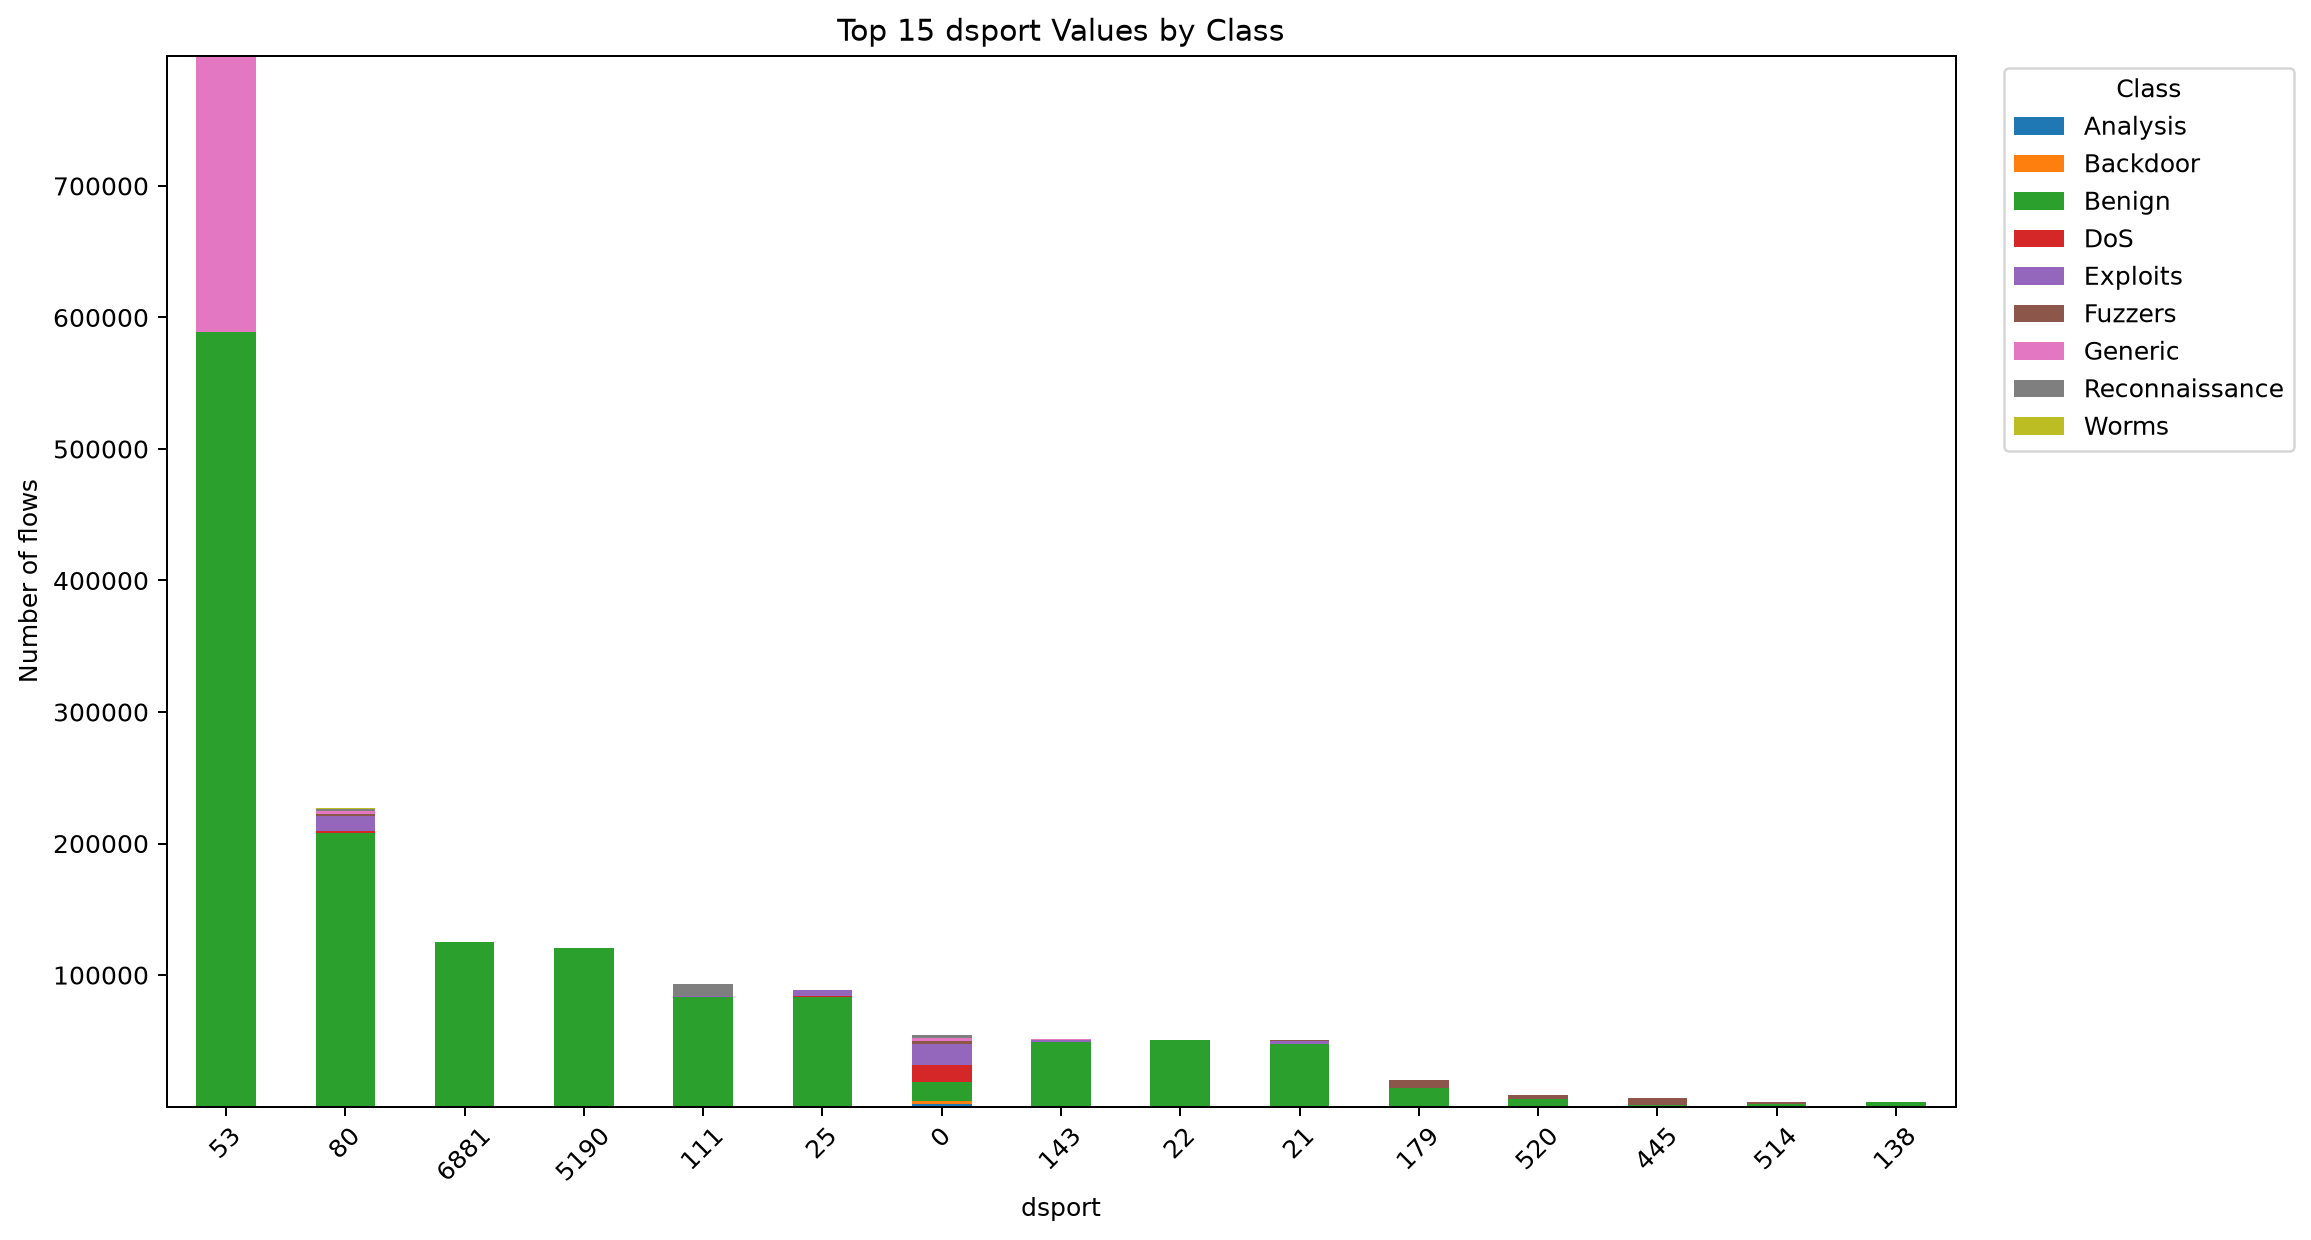

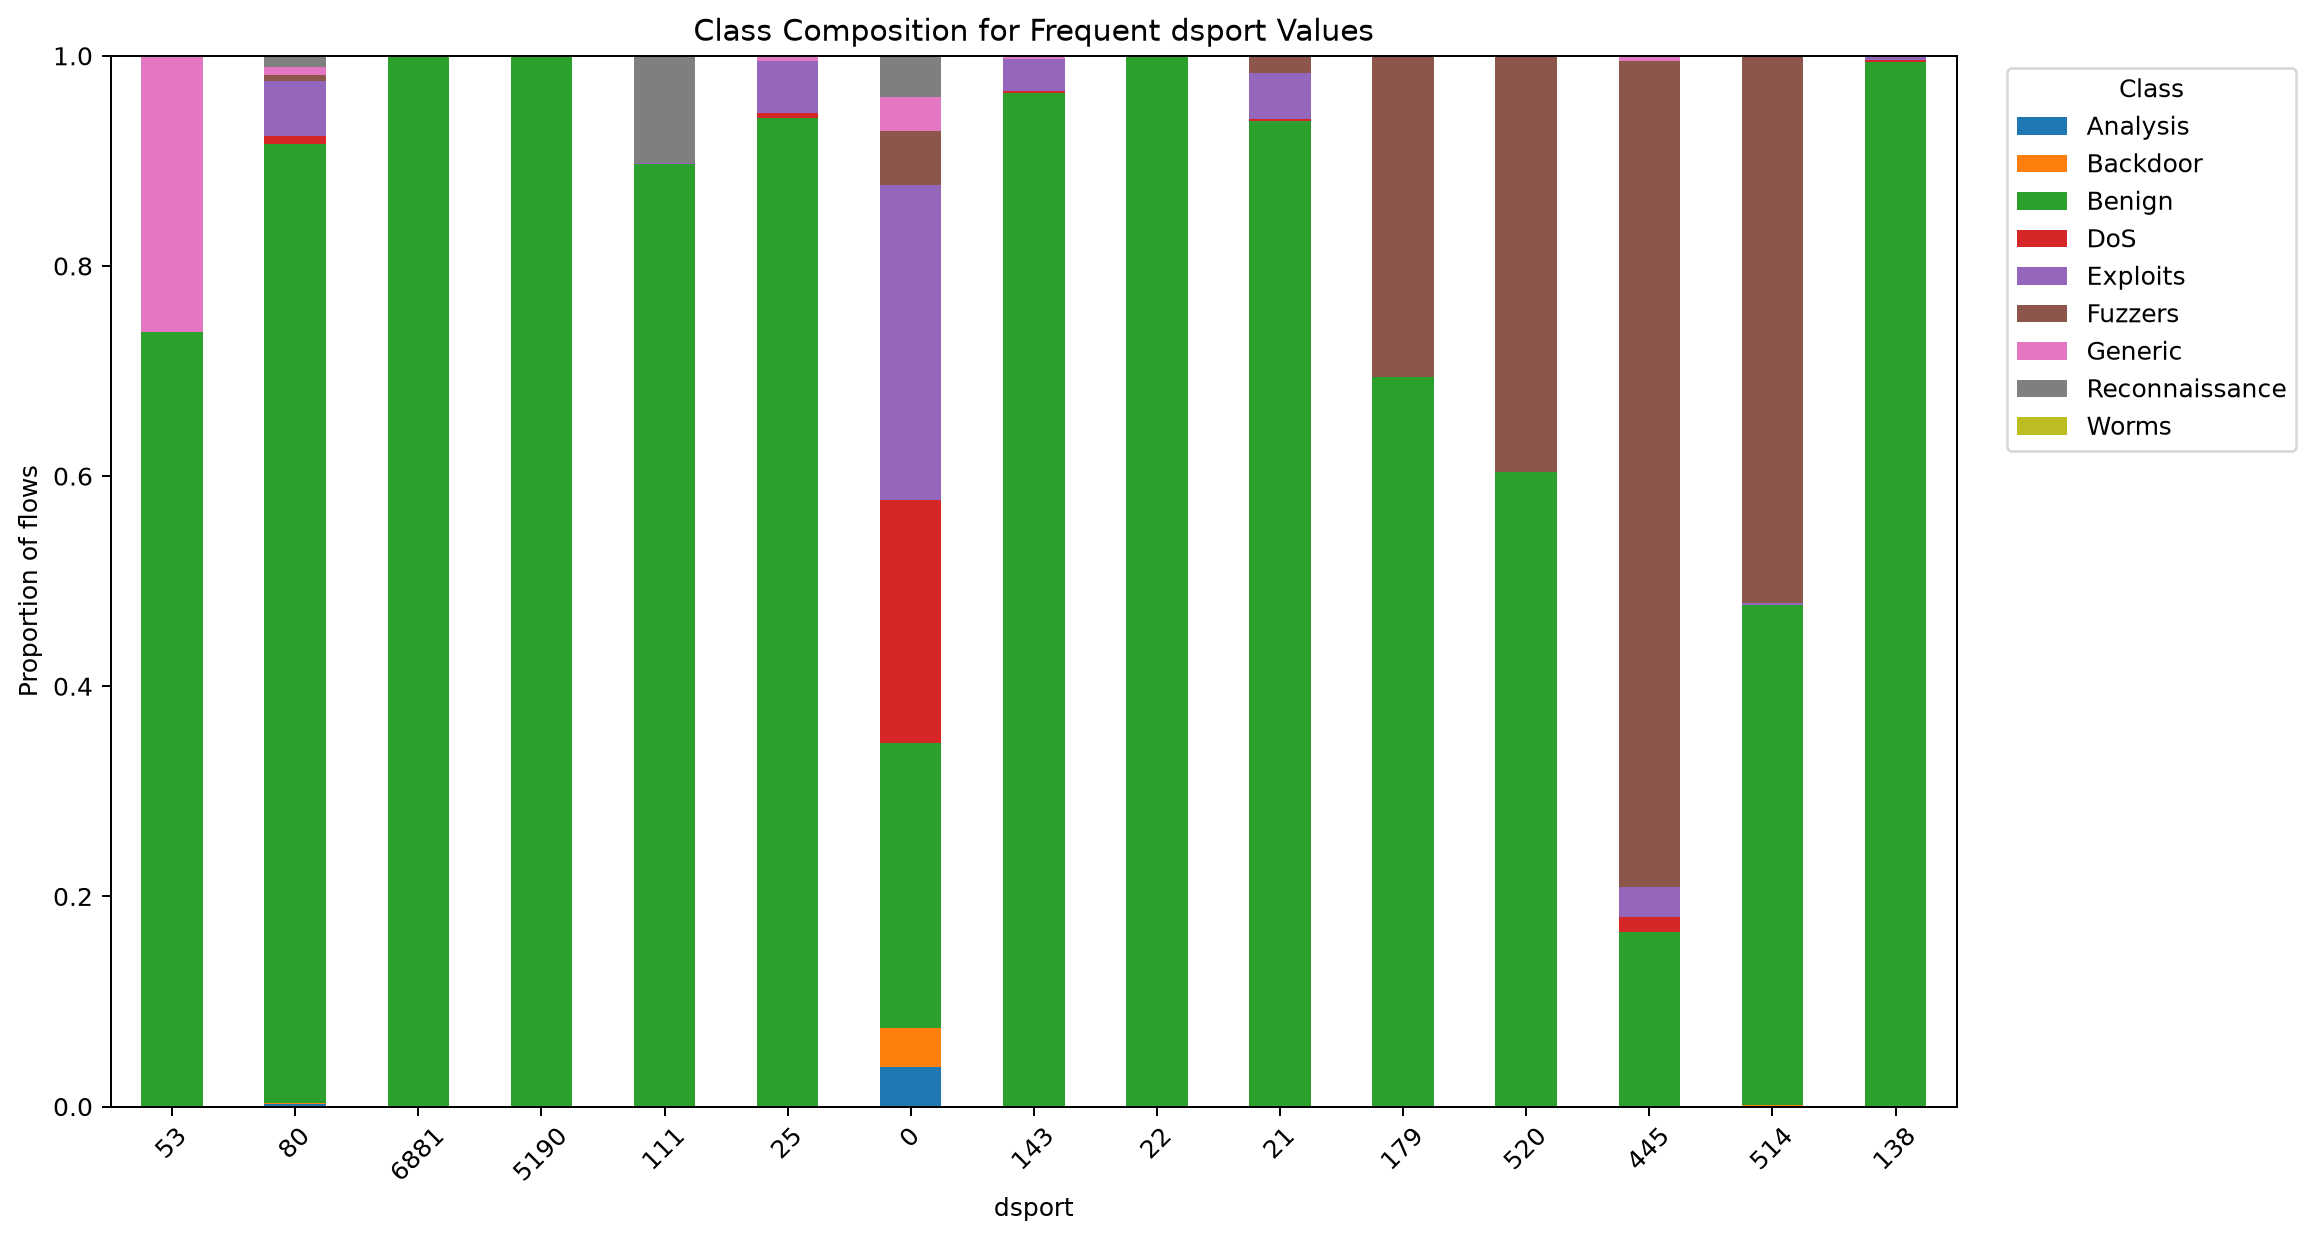

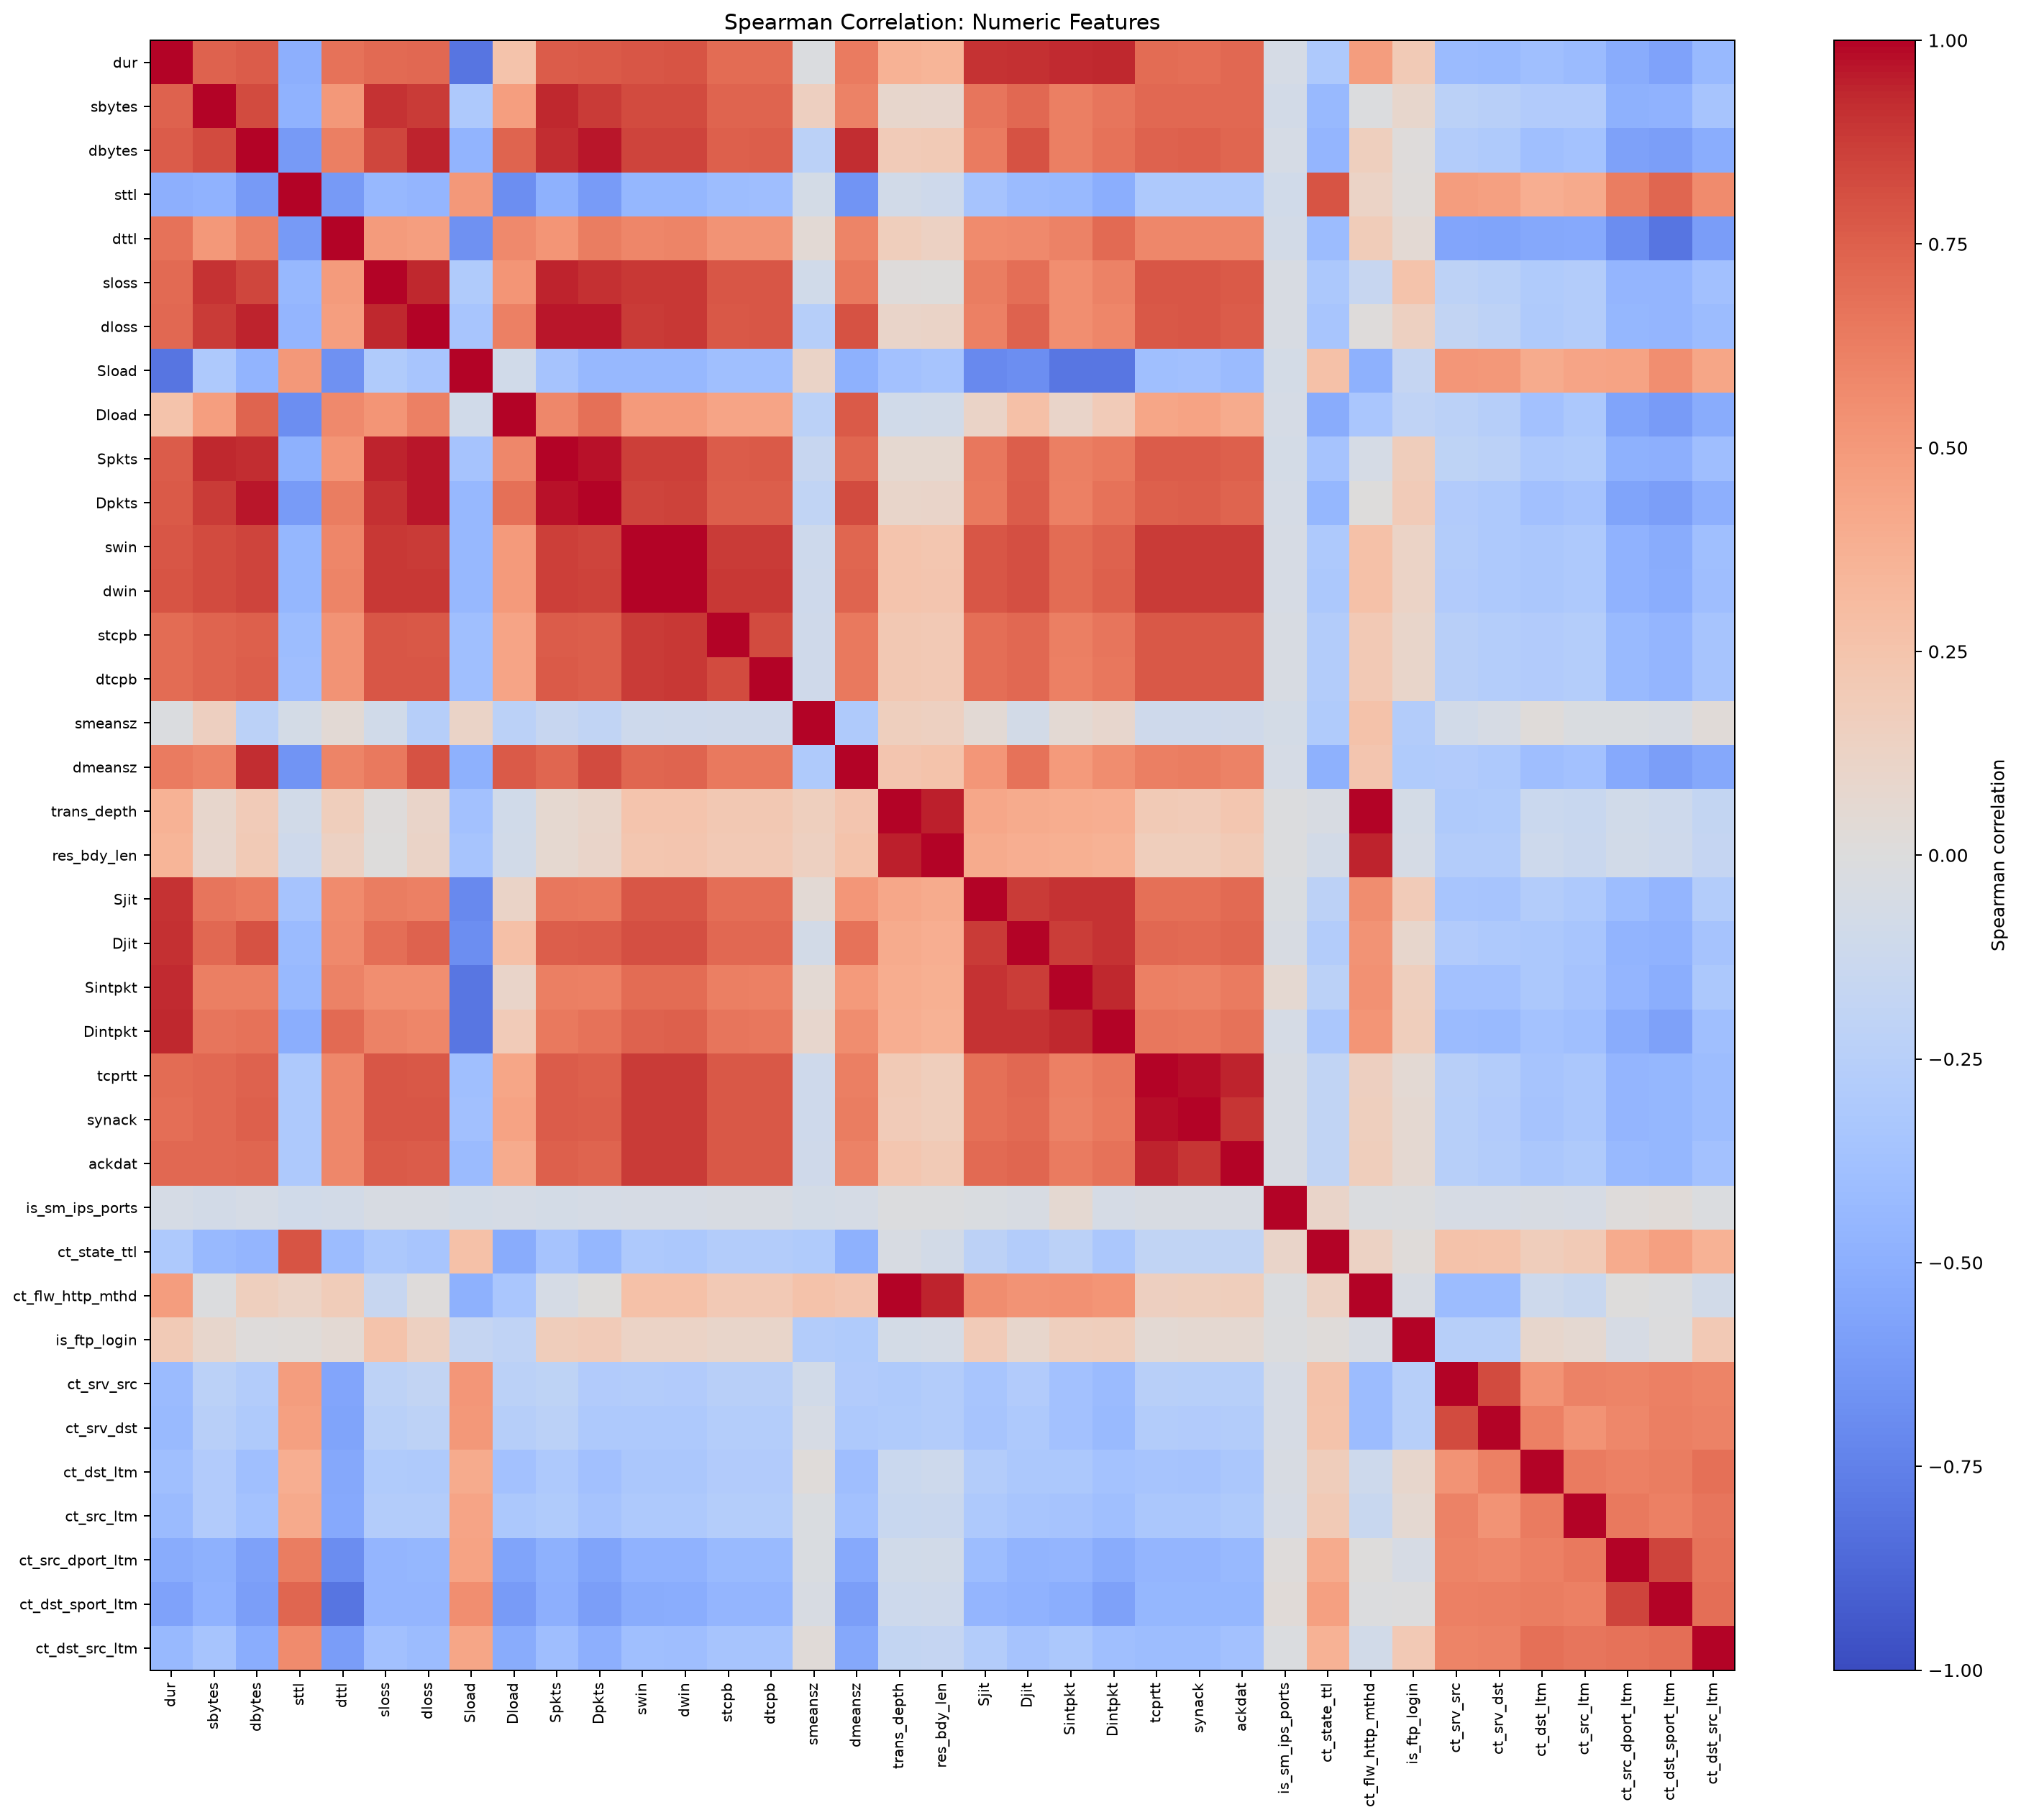

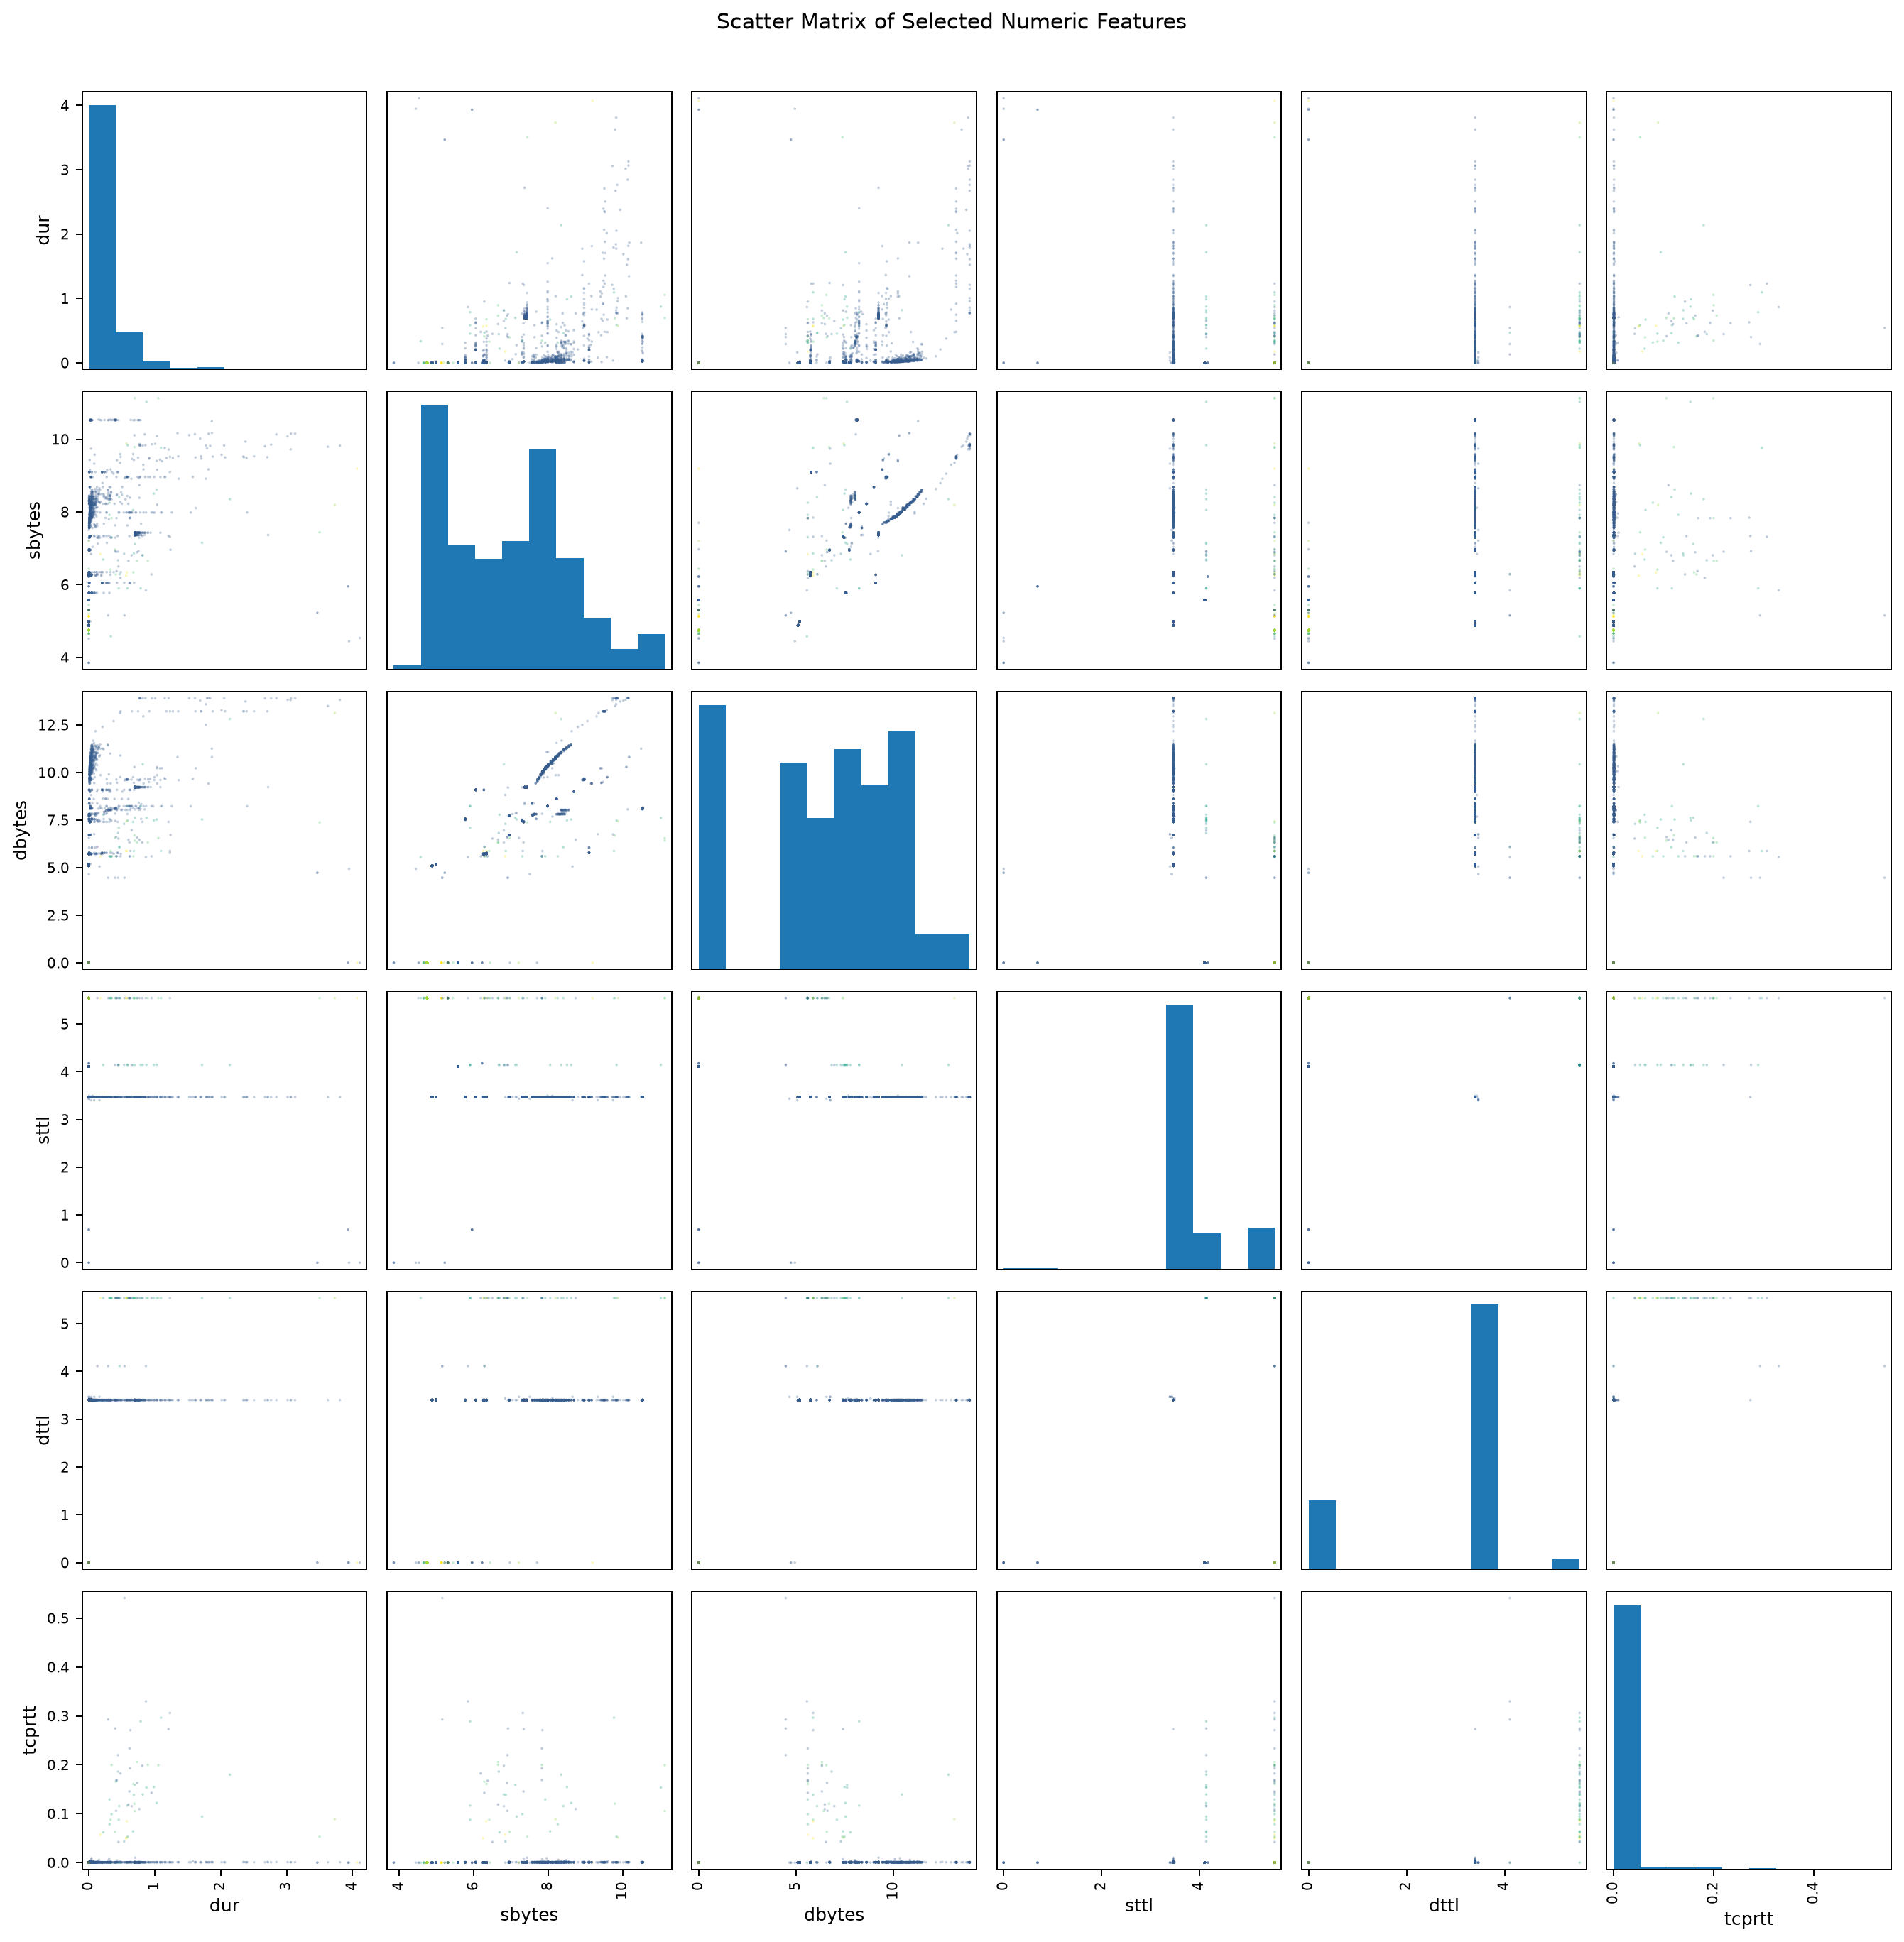

Done.


In [8]:
import matplotlib.image as mpimg

order = [
    "01_class_distribution.png",
    "02_class_distribution_log.png",
    "03_classes_over_time.png",
    "04_class_proportions_over_time.png",
    "05_sport_counts_by_class.png",
    "06_sport_class_proportions.png",
    "05_dsport_counts_by_class.png",
    "06_dsport_class_proportions.png",
    "07_numeric_correlation_matrix.png",
    "08_scatter_matrix.png",
]

for name in order:
    p = OUT / name
    if not p.is_file():
        print(f"(missing) {name}")
        continue
    display(HTML(f"<h4>{name}</h4>"))
    display(Image(filename=str(p)))

print("Done.")